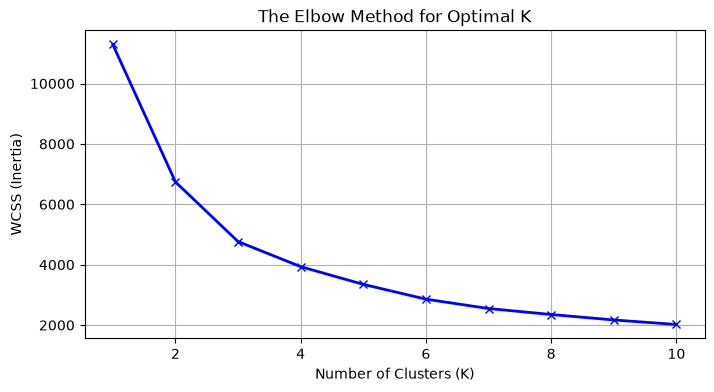


--- K-Means Cluster Distribution (K=3) ---
KMeans_Cluster
2    996
0    975
1    852
Name: count, dtype: int64


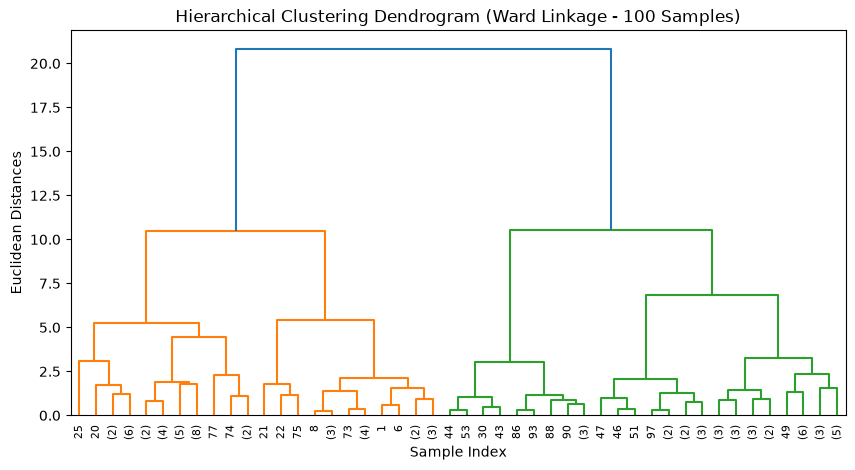


--- Hierarchical Cluster Distribution (K=3) ---
Hierarchical_Cluster
0    1204
1     934
2     685
Name: count, dtype: int64


In [1]:
# ==============================================================================
# ASSIGNMENT 6: K-MEANS & HIERARCHICAL CLUSTERING ON SALES DATA
# ==============================================================================
# ALGORITHM & OBJECTIVE:
#   Segment transactional sales data into cohesive groupings.
#   1. Preprocessing: Select numerical customer purchasing metrics (e.g.,
#      QUANTITYORDERED, PRICEEACH, SALES, MSRP).
#   2. Feature Normalization: Standardization ensures distance symmetry across scales.
#   3. Elbow Method:
#      - Compute Within-Cluster Sum of Squares (WCSS / Inertia) for K in [1, 10].
#      - Identify the inflection point ("elbow") where rate of variance explanation plateaus.
#   4. K-Means Clustering: Lloyd's algorithm iteratively alternates between
#      cluster assignment and centroid re-computation.
#   5. Agglomerative Hierarchical Clustering: Bottom-up Ward's minimum variance linkage.
#
# TIME & SPACE COMPLEXITIES:
#   - K-Means:
#       * Time Complexity: O(I * K * N * D), where I = iterations, K = clusters,
#         N = samples, D = features.
#       * Space Complexity: O(N * D + K * D) to maintain dataset and centroids.
#   - Hierarchical (Agglomerative) Clustering:
#       * Time Complexity: O(N^2 * log(N)) using priority queues with Ward linkage.
#       * Space Complexity: O(N^2) to compute and hold pairwise proximity matrix.
# ==============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

# Load dataset with fallback encoding for non-standard CSV characters
df = pd.read_csv('sales_data_sample.csv', encoding='unicode_escape')

# Select relevant numeric features for customer/order segmentation
features = ['QUANTITYORDERED', 'PRICEEACH', 'SALES', 'MSRP']
X = df[features].dropna()

# Normalize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ---------------------------------------------------------
# Step 1: Determine Optimal K via Elbow Method
# ---------------------------------------------------------
wcss = []
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(k_range, wcss, 'bx-', linewidth=2)
plt.title('The Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS (Inertia)')
plt.grid(True)
plt.show()

# ---------------------------------------------------------
# Step 2: Fit K-Means with Optimal K (e.g., K=3 or K=4 from elbow)
# ---------------------------------------------------------
optimal_k = 3
kmeans_final = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)
cluster_labels_km = kmeans_final.fit_predict(X_scaled)
X['KMeans_Cluster'] = cluster_labels_km

print(f"\n--- K-Means Cluster Distribution (K={optimal_k}) ---")
print(X['KMeans_Cluster'].value_counts())

# ---------------------------------------------------------
# Step 3: Agglomerative Hierarchical Clustering
# ---------------------------------------------------------
# Using sample subset for clear dendrogram rendering
sample_subset = X_scaled[:100]

plt.figure(figsize=(10, 5))
plt.title("Hierarchical Clustering Dendrogram (Ward Linkage - 100 Samples)")
linkage_matrix = linkage(sample_subset, method='ward')
dendrogram(linkage_matrix, truncate_mode='level', p=5)
plt.xlabel("Sample Index")
plt.ylabel("Euclidean Distances")
plt.show()

# Fit Agglomerative Clustering
agg_clustering = AgglomerativeClustering(n_clusters=optimal_k, metric='euclidean', linkage='ward')
X['Hierarchical_Cluster'] = agg_clustering.fit_predict(X_scaled)

print(f"\n--- Hierarchical Cluster Distribution (K={optimal_k}) ---")
print(X['Hierarchical_Cluster'].value_counts())